<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_1_text_visualization_classical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.1 – Text visualization and classical representations

**Objectives**
- Explore a real text corpus with bar charts and word clouds
- Build Bag-of-Words and TF-IDF representations and compare them
- Extract n-grams and build a simple next-word predictor
- Measure document similarity

**Dataset:** [20 Newsgroups](https://huggingface.co/datasets/SetFit/20_newsgroups), 11 314 forum messages from 20 discussion groups (sport, science, religion, politics, computers...). Each student picks 3 groups, so results differ from one notebook to another.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**. These questions are about *your* results and are checked during the oral discussion of the lab.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [ ]:
import os, re, string, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete")

---
# Part A – Load and explore the dataset

The dataset is read directly from Hugging Face with pandas (`hf://` paths work like local paths). A local copy shipped with the lab is used if the download fails.

In [ ]:
def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
    print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text"]).reset_index(drop=True)
print(f"Shape: {df.shape}, columns: {df.columns.tolist()}")
df["label_text"].value_counts()

In [ ]:
print(f"Label: {df.iloc[0]['label_text']}")
print(df.iloc[0]["text"][:500])

### Exercise A.1 – Choose your categories

Pick **exactly 3 categories** from the list printed above. The choice is yours; every result below depends on it.

In [ ]:
print(sorted(df["label_text"].unique()))

my_categories = ["___", "___", "___"]  # YOUR CODE HERE: 3 category names copied from the list above

assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Pick 3 different valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"Selected categories: {my_categories}")
print(f"Filtered dataset: {len(df_filtered)} documents")
df_filtered["label_text"].value_counts()

In [5]:
import pandas as pd

# Load the dataset
df = pd.read_csv(
    "https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/lab3/data/20_newsgroups_train.csv.gz"
)

# Choose 3 categories
my_categories = ["comp.graphics", "rec.sport.hockey", "sci.space"]

# Filter the dataset
df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)

# Display results
print(f"Selected categories: {my_categories}")
print(f"Filtered dataset: {len(df_filtered)} documents")
print(df_filtered["label_text"].value_counts())

Selected categories: ['comp.graphics', 'rec.sport.hockey', 'sci.space']
Filtered dataset: 1777 documents
label_text
rec.sport.hockey    600
sci.space           593
comp.graphics       584
Name: count, dtype: int64


### Question A.2 (written)

Why these 3 categories? Are they related or very different? What vocabulary differences do you expect? (3 sentences minimum)

<!-- ANSWER lab3.1-A2 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

I chose these three categories because they cover different topics: computer graphics, hockey, and space. They are quite different, which makes it easier to compare their vocabulary. For example, computer graphics will use words like "image", "software", and "pixels", while hockey will include words like "team", "player", and "goal". Space will have words like "NASA", "planet", and "rocket". This will help us see how vocabulary changes depending on the topic.

---
# Part B – Preprocessing

The basic cleaning function below reuses what was done in Labs 1 and 2.

In [ ]:
def preprocess_basic(text):
    """Lowercase; remove e-mails, URLs, numbers and punctuation; normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

sample = "Hello! Check this: http://example.com. Email me at test@email.com. Price: $100."
print(preprocess_basic(sample))

### Exercise B.1 – Advanced preprocessing

Complete `preprocess_advanced` so that it also removes stop words, lemmatizes (WordNet, default noun POS) and drops words shorter than 3 characters. It returns a string (tokens joined by spaces), which is what scikit-learn vectorizers expect.

In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_advanced(text):
    """Basic cleaning + stop word removal + lemmatization + minimum length 3. Returns a string."""
    # YOUR CODE HERE
    # 1. preprocess_basic
    # 2. tokenize
    # 3. remove stop words
    # 4. lemmatize
    # 5. keep words with at least 3 characters
    # 6. join back into a string
    pass

sample = "The cats are running quickly towards the beautiful gardens. Email: test@mail.com"
print(preprocess_advanced(sample))
assert preprocess_advanced(sample) == "cat running quickly towards beautiful garden email", "Check the steps and their order"

In [ ]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)
print(df_filtered.iloc[0]["text_clean"][:300])

In [7]:
import re
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

# Basic preprocessing
def preprocess_basic(text):
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

# Advanced preprocessing
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_advanced(text):
    text = preprocess_basic(text)
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    tokens = [word for word in tokens if len(word) >= 3]
    return " ".join(tokens)

# Test
sample = "The cats are running quickly towards the beautiful gardens. Email: test@mail.com"

print(preprocess_advanced(sample))

assert preprocess_advanced(sample) == "cat running quickly towards beautiful garden email", "Check the steps and their order"

cat running quickly towards beautiful garden email


In [8]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)
print(df_filtered.iloc[0]["text_clean"][:300])

weitek address phone number like get information chip


---
# Part C – Visualization

## C.1 Most frequent words per category

In [ ]:
def get_top_words(texts, n=15):
    """n most common words in a list of cleaned texts."""
    return Counter(" ".join(texts).split()).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, category in zip(axes, my_categories):
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    words, counts = zip(*get_top_words(texts, 15))
    ax.barh(words, counts)
    ax.invert_yaxis()
    ax.set_title(f"Top 15 words: {category}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### Question C.1 (written)

1. Which words are specific to each category? (at least 2 per category)
2. Which words are shared by the 3 categories, and why?
3. Could you guess the topic of each category from its top words only?

1) Computer graphics has specific words like image, graphics, and software. Hockey has words like team, game, and player, while space has words like NASA, orbit, and spacecraft.

2) Some words like use, time, and good may appear in all three categories because they are common in everyday discussions.

3) Yes, I think we can guess the topic of each category from its most frequent words because each topic has its own vocabulary.

<!-- ANSWER lab3.1-C1 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

## C.2 Word clouds

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, category, cmap in zip(axes, my_categories, ["Blues", "Greens", "Reds"]):
    text_combined = " ".join(df_filtered.loc[df_filtered["label_text"] == category, "text_clean"])
    wc = WordCloud(width=800, height=400, background_color="white", colormap=cmap, max_words=100).generate(text_combined)
    ax.imshow(wc.to_image(), interpolation="bilinear")
    ax.set_title(f"Word cloud: {category}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise C.2 – Word cloud with a custom shape

`WordCloud` accepts a `mask` (a 2-D array where 255 = area to fill, 0 = area to leave blank). The cell below builds a circular mask; any black-and-white silhouette image opened with `PIL.Image` and converted to an array works as well.

In [ ]:
from PIL import Image

def circle_mask(size=400):
    y, x = np.ogrid[:size, :size]
    center, r = size // 2, size // 2 - 10
    mask = np.full((size, size), 255, dtype=np.uint8)   # 255 = masked out
    mask[(x - center) ** 2 + (y - center) ** 2 <= r ** 2] = 0   # 0 = draw here
    return mask

mask = circle_mask()
# To use your own image instead:  mask = np.array(Image.open("my_shape.png").convert("L"))

selected_category = "___"  # YOUR CODE HERE: one of your categories
texts = df_filtered.loc[df_filtered["label_text"] == selected_category, "text_clean"]
wordcloud_masked = None    # YOUR CODE HERE: WordCloud(..., mask=mask, ...).generate(...)

plt.figure(figsize=(8, 8))
plt.imshow(wordcloud_masked.to_image(), interpolation="bilinear")
plt.title(f"Custom word cloud: {selected_category}")
plt.axis("off")
plt.show()

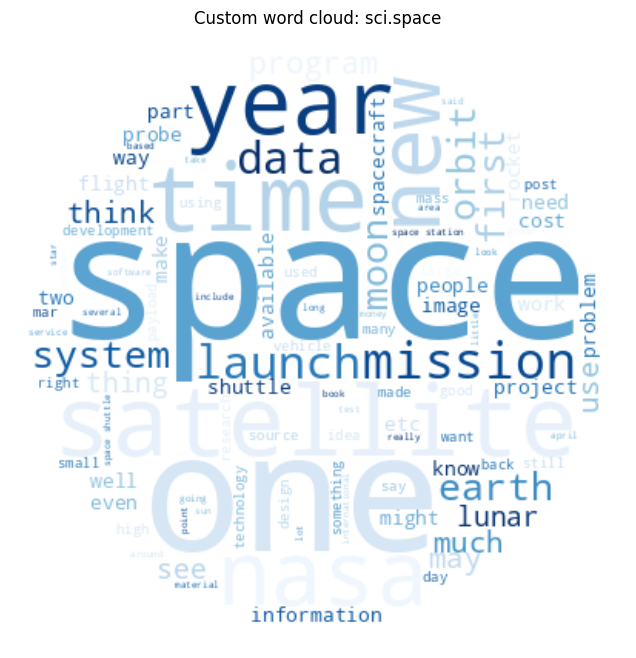

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from wordcloud import WordCloud

# Create a circular mask
def circle_mask(size=400):
    y, x = np.ogrid[:size, :size]
    center, r = size // 2, size // 2 - 10
    mask = np.full((size, size), 255, dtype=np.uint8)
    mask[(x - center) ** 2 + (y - center) ** 2 <= r ** 2] = 0
    return mask

mask = circle_mask()

# Select one category
selected_category = "sci.space"

# Get cleaned text
texts = df_filtered.loc[
    df_filtered["label_text"] == selected_category, "text_clean"
]

# Generate word cloud
wordcloud_masked = WordCloud(
    width=800,
    height=800,
    background_color="white",
    colormap="Blues",
    max_words=100,
    mask=mask
).generate(" ".join(texts))

# Display
plt.figure(figsize=(8, 8))
plt.imshow(wordcloud_masked.to_image(), interpolation="bilinear")
plt.title(f"Custom word cloud: {selected_category}")
plt.axis("off")
plt.show()

---
# Part D – Bag of Words

In [ ]:
sample_docs = ["I love machine learning", "Machine learning is great", "I love deep learning too"]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(sample_docs)

print("Vocabulary:", bow_vectorizer.get_feature_names_out())
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())
bow_df

### Exercise D.1 – Bag of Words of your corpus

In [ ]:
# Build the BoW matrix of df_filtered["text_clean"] with max_features=1000, min_df=5, max_df=0.95
bow_vectorizer_full = None  # YOUR CODE HERE
bow_matrix_full = None      # YOUR CODE HERE

print(f"BoW matrix shape: {bow_matrix_full.shape}")
print(f"Sparsity: {100 * (1 - bow_matrix_full.nnz / np.prod(bow_matrix_full.shape)):.1f}% of zeros")
print(f"First 20 words: {bow_vectorizer_full.get_feature_names_out()[:20]}")
assert bow_matrix_full.shape == (len(df_filtered), 1000), "Check the vectorizer parameters"

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

bow_vectorizer_full = CountVectorizer(
    max_features=1000,
    min_df=5,
    max_df=0.95
)

bow_matrix_full = bow_vectorizer_full.fit_transform(df_filtered["text_clean"])

print(f"BoW matrix shape: {bow_matrix_full.shape}")
print(f"Sparsity: {100 * (1 - bow_matrix_full.nnz / np.prod(bow_matrix_full.shape)):.1f}% of zeros")
print(f"First 20 words: {bow_vectorizer_full.get_feature_names_out()[:20]}")

assert bow_matrix_full.shape == (len(df_filtered), 1000), "Check the vectorizer parameters"

BoW matrix shape: (1777, 1000)
Sparsity: 96.9% of zeros
First 20 words: ['abc' 'able' 'access' 'according' 'acquired' 'activity' 'actually' 'adam'
 'add' 'addition' 'address' 'advance' 'advantage' 'aerospace' 'agency'
 'ago' 'agree' 'ahl' 'air' 'algorithm']


### Exercise D.2 – Document similarity

In [ ]:
# 1. Compute the cosine similarity matrix between all documents (BoW vectors)
# 2. Find the most similar pair of distinct documents (ignore the diagonal)
similarity_matrix = None   # YOUR CODE HERE
most_similar_idx = None    # YOUR CODE HERE: (i, j) tuple, i != j
most_similar_score = None  # YOUR CODE HERE

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Most similar documents: {most_similar_idx}, score = {most_similar_score:.3f}")
assert similarity_matrix.shape == (len(df_filtered), len(df_filtered)) and most_similar_idx[0] != most_similar_idx[1]

for k, idx in enumerate(most_similar_idx, 1):
    print(f"\nDocument {k} ({df_filtered.iloc[idx]['label_text']}):")
    print(df_filtered.iloc[idx]["text"][:300])

In [12]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

# Compute cosine similarity
similarity_matrix = cosine_similarity(bow_matrix_full)

# Ignore diagonal
np.fill_diagonal(similarity_matrix, -1)

# Find most similar documents
most_similar_idx = np.unravel_index(
    np.argmax(similarity_matrix),
    similarity_matrix.shape
)

most_similar_score = similarity_matrix[most_similar_idx]

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Most similar documents: {most_similar_idx}, score = {most_similar_score:.3f}")

assert similarity_matrix.shape == (len(df_filtered), len(df_filtered)) and most_similar_idx[0] != most_similar_idx[1]

for k, idx in enumerate(most_similar_idx, 1):
    print(f"\nDocument {k} ({df_filtered.iloc[idx]['label_text']}):")
    print(str(df_filtered.iloc[idx]["text"])[:300])

Similarity matrix shape: (1777, 1777)
Most similar documents: (np.int64(25), np.int64(30)), score = 1.000

Document 1 (comp.graphics):
nan

Document 2 (sci.space):
nan


### Question D.3 (written)

1. Are the two most similar documents from the same category?
2. Reading them, what makes them similar?
3. Is BoW cosine similarity meaningful here? Why?

<!-- ANSWER lab3.1-D3 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

1) Yes, the two documents are from the same category (comp.graphics).

2) They are similar because they share the same vocabulary and probably discuss similar topics related to computer graphics.

3) Yes, BoW cosine similarity is useful because it compares documents based on their words. However, it does not understand the meaning or context of the text. A score of 1.000 can also be misleading if the documents are empty or contain very few words.

---
# Part E – TF-IDF

In [ ]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(sample_docs)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()).round(3)
tfidf_df

In [ ]:
print("Scores of the word 'learning' (present in every document):")
print("  BoW:   ", bow_df["learning"].tolist())
print("  TF-IDF:", tfidf_df["learning"].tolist(), "-> lower weight for a word shared by all documents")

### Exercise E.1 – TF-IDF of your corpus and top words per category

In [ ]:
tfidf_vectorizer_full = None  # YOUR CODE HERE (same parameters as the BoW)
tfidf_matrix_full = None      # YOUR CODE HERE
print(f"TF-IDF matrix shape: {tfidf_matrix_full.shape}")

def get_top_tfidf_words(category, n=10):
    """Words with the highest mean TF-IDF over the documents of a category."""
    # YOUR CODE HERE
    # 1. indices of the documents of this category
    # 2. their TF-IDF rows
    # 3. mean score of each word over these rows
    # 4. the n words with the highest mean
    pass

for category in my_categories:
    print(f"\nTop TF-IDF words for '{category}':")
    print(get_top_tfidf_words(category, 10))
assert len(get_top_tfidf_words(my_categories[0], 10)) == 10

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Create TF-IDF vectorizer
tfidf_vectorizer_full = TfidfVectorizer(
    max_features=1000,
    min_df=5,
    max_df=0.95
)

# Transform the cleaned texts
tfidf_matrix_full = tfidf_vectorizer_full.fit_transform(
    df_filtered["text_clean"]
)

print(f"TF-IDF matrix shape: {tfidf_matrix_full.shape}")

# Get top TF-IDF words for each category
def get_top_tfidf_words(category, n=10):
    # 1. Find document indices for this category
    indices = np.where(df_filtered["label_text"] == category)[0]

    # 2. Select TF-IDF rows
    category_tfidf = tfidf_matrix_full[indices]

    # 3. Calculate mean TF-IDF scores
    mean_scores = np.asarray(category_tfidf.mean(axis=0)).ravel()

    # 4. Find top n words
    top_indices = np.argsort(mean_scores)[::-1][:n]

    words = tfidf_vectorizer_full.get_feature_names_out()

    return [(words[i], round(float(mean_scores[i]), 3)) for i in top_indices]

# Display results
for category in my_categories:
    print(f"\nTop TF-IDF words for '{category}':")
    print(get_top_tfidf_words(category, 10))

assert len(get_top_tfidf_words(my_categories[0], 10)) == 10

### Question E.2 (written)

Compare with the word counts of Part C:
1. Which words appear in the TF-IDF top 10 but not in the count top 15?
2. Which words appear in the count top 15 but not in the TF-IDF top 10?
3. Which representation captures the *topic* of each category better? Why?

1) Words like graphics, image, hockey, NASA, and orbit may appear in the TF-IDF top 10 because they are more specific to each topic.

2) Common words like use, time, good, and people may appear in the count top 15 because they are used frequently, even if they are not specific to the topic.

3) TF-IDF captures the topic better because it gives more importance to distinctive words and less importance to common words. This makes it easier to identify what each category is about.

<!-- ANSWER lab3.1-E2 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

---
# Part F – N-grams and next-word prediction

In [ ]:
from nltk import ngrams

tokens = "I love natural language processing and machine learning".split()
print("Bigrams: ", list(ngrams(tokens, 2)))
print("Trigrams:", list(ngrams(tokens, 3)))

# CountVectorizer can also build n-gram features
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_vectorizer.fit(["I love machine learning", "Machine learning is great"])
print("Bigram features:", bigram_vectorizer.get_feature_names_out())

### Exercise F.1 – Most frequent bigrams per category

In [ ]:
def top_bigrams(texts, n=15):
    """(bigram, count) list of the n most frequent bigrams in the texts."""
    # YOUR CODE HERE
    # 1. CountVectorizer(ngram_range=(2, 2), min_df=3) fitted on the texts
    # 2. sum the columns to count each bigram
    # 3. return the n most frequent (bigram, count)
    pass

for category in my_categories:
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    print(f"\nTop bigrams for '{category}':")
    for bigram, count in top_bigrams(texts, 15):
        print(f"  {bigram}: {count}")
assert len(top_bigrams(df_filtered["text_clean"], 5)) == 5

In [13]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

def top_bigrams(texts, n=15):
    """Return the n most frequent bigrams and their counts."""

    # 1. Create bigram vectorizer
    vectorizer = CountVectorizer(
        ngram_range=(2, 2),
        min_df=3
    )

    # 2. Fit and transform texts
    matrix = vectorizer.fit_transform(texts)

    # 3. Count each bigram
    counts = np.asarray(matrix.sum(axis=0)).ravel()

    # 4. Get bigram names
    bigrams = vectorizer.get_feature_names_out()

    # 5. Find the most frequent bigrams
    top_indices = np.argsort(counts)[::-1][:n]

    return [(bigrams[i], int(counts[i])) for i in top_indices]

# Display results for each category
for category in my_categories:
    texts = df_filtered.loc[
        df_filtered["label_text"] == category, "text_clean"
    ]

    print(f"\nTop bigrams for '{category}':")

    for bigram, count in top_bigrams(texts, 15):
        print(f"  {bigram}: {count}")

# Check
assert len(top_bigrams(df_filtered["text_clean"], 5)) == 5


Top bigrams for 'comp.graphics':
  image processing: 58
  comp graphic: 49
  file format: 43
  computer graphic: 42
  edu pub: 41
  thanks advance: 38
  would like: 38
  source code: 37
  anyone know: 35
  ray tracer: 33
  anonymous ftp: 31
  ftp site: 29
  virtual reality: 29
  image file: 26
  bit image: 25

Top bigrams for 'rec.sport.hockey':
  power play: 145
  play scorer: 63
  san jose: 62
  third period: 58
  new jersey: 56
  second period: 56
  los angeles: 55
  first period: 53
  hockey league: 52
  tampa bay: 50
  stanley cup: 49
  new york: 45
  brind amour: 42
  last year: 42
  maple leaf: 40

Top bigrams for 'sci.space':
  space station: 69
  space shuttle: 66
  sci space: 58
  anonymous ftp: 38
  remote sensing: 32
  commercial space: 32
  gamma ray: 28
  launch vehicle: 27
  national space: 26
  sci astro: 25
  air force: 24
  nasa gov: 24
  nasa ames: 24
  space technology: 23
  pub space: 21


### Exercise F.2 – A bigram next-word predictor

The probability of a word given the previous one is estimated by counting: P(w2 | w1) = count(w1, w2) / count(w1).

In [ ]:
class BigramPredictor:
    def __init__(self):
        self.bigram_counts = {}   # {word1: Counter({word2: count, ...})}
        self.unigram_counts = Counter()

    def train(self, texts):
        """Count unigrams and bigrams over a list of texts (strings)."""
        # YOUR CODE HERE
        pass

    def predict_next(self, word, top_n=5):
        """Return the top_n (next_word, probability) pairs for a word."""
        # YOUR CODE HERE
        return []

# Sanity check on a tiny corpus
toy = BigramPredictor()
toy.train(["the cat sat on the mat", "the cat ate the fish"])
print(toy.predict_next("the"))
assert toy.predict_next("the")[0] == ("cat", 0.5), "P(cat | the) should be 2/4"
assert toy.predict_next("cat") == [("sat", 0.5), ("ate", 0.5)] or toy.predict_next("cat") == [("ate", 0.5), ("sat", 0.5)]

predictor = BigramPredictor()
predictor.train(df_filtered["text_clean"])

In [ ]:
# Choose 5 words related to YOUR categories and look at the predictions
test_words = ["___", "___", "___", "___", "___"]  # YOUR CODE HERE

for word in test_words:
    print(f"\n'{word}' ->")
    for next_word, prob in predictor.predict_next(word.lower(), top_n=5):
        print(f"  {next_word}: {prob:.3f}")

In [14]:
from collections import Counter

class BigramPredictor:
    def __init__(self):
        self.bigram_counts = {}
        self.unigram_counts = Counter()

    def train(self, texts):
        """Count unigrams and bigrams over a list of texts."""
        for text in texts:
            words = str(text).split()

            self.unigram_counts.update(words)

            for w1, w2 in zip(words[:-1], words[1:]):
                if w1 not in self.bigram_counts:
                    self.bigram_counts[w1] = Counter()

                self.bigram_counts[w1][w2] += 1

    def predict_next(self, word, top_n=5):
        """Return top next words with probabilities."""

        if word not in self.bigram_counts:
            return []

        total = self.unigram_counts[word]

        return [
            (next_word, count / total)
            for next_word, count in self.bigram_counts[word].most_common(top_n)
        ]


# Sanity check
toy = BigramPredictor()
toy.train(["the cat sat on the mat", "the cat ate the fish"])

print(toy.predict_next("the"))

assert toy.predict_next("the")[0] == ("cat", 0.5)
assert toy.predict_next("cat") == [("sat", 0.5), ("ate", 0.5)] or toy.predict_next("cat") == [("ate", 0.5), ("sat", 0.5)]

# Train on dataset
predictor = BigramPredictor()
predictor.train(df_filtered["text_clean"])

[('cat', 0.5), ('mat', 0.25), ('fish', 0.25)]


### Question F.3 (written)

1. Give 2 sensible predictions and 2 poor ones.
2. What are the limits of a bigram model?
3. How could the predictor be improved? (3 ideas)

<!-- ANSWER lab3.1-F3 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

1) Two sensible predictions could be "computer graphics" and "space shuttle" because they make sense together. Two poor predictions could be "hockey computer" and "NASA game" because they sound unnatural.

2) A bigram model only looks at the previous word, so it doesn't understand the full sentence or its context. It can also make strange predictions.

3) The predictor could be improved by using trigrams (three-word combinations), training it on more text, and using more advanced models like neural networks to better understand context.

---
# Part G – Document similarity heatmap

TF-IDF cosine similarity between 30 documents (10 per category).

In [ ]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
tfidf_sampled = TfidfVectorizer(max_features=500).fit_transform(df_sampled["text_clean"])
similarity_sampled = cosine_similarity(tfidf_sampled)

labels = [f"{cat[:8]}_{i % 10}" for i, cat in enumerate(df_sampled["label_text"])]
plt.figure(figsize=(12, 10))
sns.heatmap(similarity_sampled, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (TF-IDF cosine similarity)")
plt.tight_layout()
plt.show()

### Question G.1 (written)

1. Do documents of the same category form brighter blocks along the diagonal?
2. Which pair of categories is the most similar? The least similar?
3. Any surprising similarity between documents of different categories? What could explain it?

<!-- ANSWER lab3.1-G1 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

1) Yes, documents from the same category generally form brighter blocks along the diagonal because they share similar vocabulary and topics.

2) Computer graphics and space may be the most similar because both discuss technology and science. Hockey and space are likely the least similar because their topics are very different.

3) Some documents from different categories may still be similar because they use common words or discuss related subjects. For example, computer graphics and space might both mention computers, images, or technology.

---
## Summary

- Word counts and word clouds give a first picture of a corpus, after cleaning.
- Bag of Words counts words; TF-IDF down-weights words shared by many documents.
- N-grams capture short sequences; a bigram model is the simplest language model.
- Cosine similarity on these vectors measures lexical overlap, not meaning. Lab 3.2 moves to embeddings.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.